In [13]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)
print(A.shape, A.dtype)

(512, 512) float64


^ Importing libraries and loading an image.

In [14]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)

A_back = U @ np.diag(s) @ Vt
print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 3.234390533179976e-11


^ Decomposing A into U, s, and Vt using SVD. Then, rebuilding A.

First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


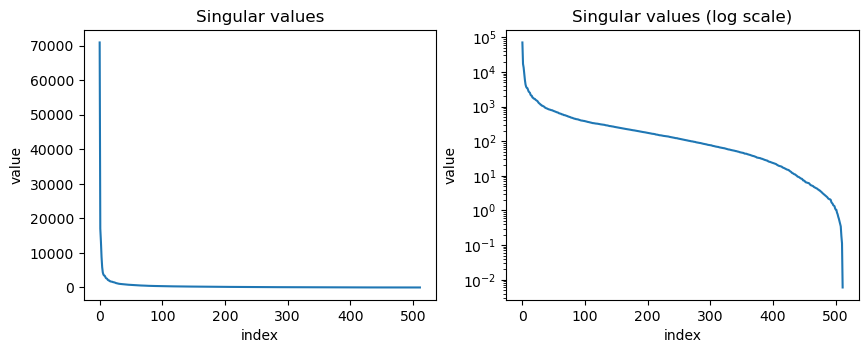

In [15]:
print("First five:", np.round(s[:5], 1))
print("50th, 200th, last:", round(s[49], 1),
round(s[199], 1), round(s[-1], 3))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(s)
ax1.set(title="Singular values", xlabel="index", ylabel="value")
ax2.semilogy(s)
ax2.set(title="Singular values (log scale)", xlabel="index", ylabel="value")
plt.show()

^ Showing the relationship between rank-1 pieces and their singular value. The "earlier" in the equation, the better.

In [16]:
def rank_k_approx(A, k):
    "Return the rank-k SVD approximation of A."
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

^ Decomposing a matrix with SVD, then rebuilding it using the first k "terms" of the SVD.


In [17]:
print("rank of A_10:", np.linalg.matrix_rank(rank_k_approx(A, 10)))
print("k = 512 gives A back?", np.allclose(rank_k_approx(A, 512), A))

stripes = np.outer([1, 0, 1, 0], [1, 1, 1, 1]).astype(float)
print("singular values of stripes:",
np.round(np.linalg.svd(stripes, compute_uv=False), 4))

rank of A_10: 10
k = 512 gives A back? True
singular values of stripes: [2.8284 0.     0.     0.    ]


^ Showing the rank of A_10 is 10 when k = 10 and that the original image is reconstructed when k = 512. Also, for the rank-1 stripes image, the SVD has only one nonzero singular value

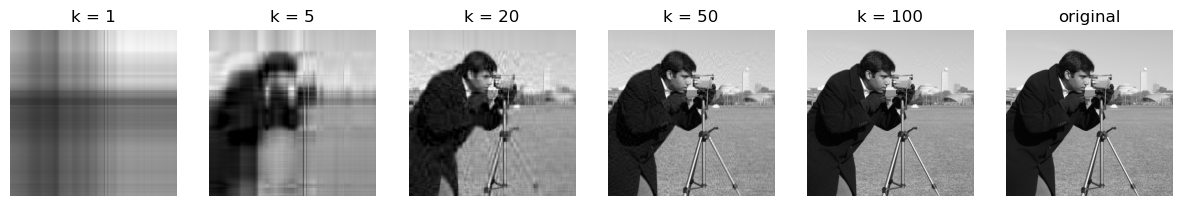

In [18]:
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))

for ax, k in zip(axes, ks):
    Ak = np.clip(rank_k_approx(A, k), 0, 255)
    ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")
plt.show()

^ Showing a comparison between different k values used for the k-approximation of A.